# Aerofit Customer Profiling Analysis
Name: Akhil Deshmukh |  Email: akdesh156@gmail.com
## 1. Defining Problem Statement and Analysing Basic Metrics

**Problem Statement**
AeroFit wants to understand the characteristics of customers purchasing KP281, KP481, and KP781 treadmills and identify factors associated with product purchase.


In [ ]:
# Import Libraries and Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
url = "https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/125/original/aerofit_treadmill.csv?1639992749"
df = pd.read_csv(url)
display(df.head())


,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,KP281,18,Male,14,Single,3,4,29562,112
1,KP281,19,Male,15,Single,2,3,31836,75
2,KP281,19,Female,14,Partnered,4,3,30699,66
3,KP281,19,Male,12,Single,3,3,32973,85
4,KP281,20,Male,13,Partnered,4,2,35247,47


In [ ]:
# Shape and Structure
print("Shape of the dataset:", df.shape)
df.info()

# Data Types
print("\nData Types:")
print(df.dtypes)

# Convert categorical variables:
categorical_cols = ['Product', 'Gender', 'MaritalStatus']
df[categorical_cols] = df[categorical_cols].astype('category')
print("\nData Types After Conversion:")
print(df.dtypes)

# Statistical Summary
display(df.describe().T)


Shape of the dataset: (180, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB

Data Types:
Product          object
Age               int64
Gender           object
Education         int64
MaritalStatus    object
Usage             int64
Fitness           int64
Income            int64
Miles             int64
dtype: object

Data Types After Conversion:
Product          category
Age                 int64
Gender          

,count,mean,std,min,25%,50%,75%,max
Age,180.0,28.788889,6.943498,18.0,24.00,26.0,33.00,50.0
Education,180.0,15.572222,1.617055,12.0,14.00,16.0,16.00,21.0
Usage,180.0,3.455556,1.084797,2.0,3.00,3.0,4.00,7.0
Fitness,180.0,3.311111,0.958869,1.0,3.00,3.0,4.00,5.0
Income,180.0,53719.577778,16506.684226,29562.0,44058.75,50596.5,58668.00,104581.0
Miles,180.0,103.194444,51.863605,21.0,66.00,94.0,114.75,360.0


**Insights**
* Dataset contains 180 rows and 9 columns.
* Product, Gender, and MaritalStatus are categorical variables.
* Age ranges from 18 to 50 years.
* Income ranges from \$29,562 to \$104,581.
* Usage ranges from 2 to 7 times per week.
* Fitness ranges from 1 to 5.
* Miles range from 21 to 360.


## 2. Non-Graphical Analysis: Value Counts and Unique Attributes
We first check the unique values and frequency of the categorical/discrete variables.


In [ ]:
for col in ['Product', 'Gender', 'MaritalStatus', 'Education', 'Usage', 'Fitness']:
    print(f"\n--- {col} ---")
    print("Number of unique values:", df[col].nunique())
    print(df[col].value_counts().sort_index())

print("\nProduct Value Counts:")
print(df['Product'].value_counts())

print("\nGender Value Counts:")
print(df['Gender'].value_counts())

print("\nMarital Status Value Counts:")
print(df['MaritalStatus'].value_counts())



--- Product ---
Number of unique values: 3
Product
KP281    80
KP481    60
KP781    40
Name: count, dtype: int64

--- Gender ---
Number of unique values: 2
Gender
Female     76
Male      104
Name: count, dtype: int64

--- MaritalStatus ---
Number of unique values: 2
MaritalStatus
Partnered    107
Single        73
Name: count, dtype: int64

--- Education ---
Number of unique values: 8
Education
12     3
13     5
14    55
15     5
16    85
18    23
20     1
21     3
Name: count, dtype: int64

--- Usage ---
Number of unique values: 6
Usage
2    33
3    69
4    52
5    17
6     7
7     2
Name: count, dtype: int64

--- Fitness ---
Number of unique values: 5
Fitness
1     2
2    26
3    97
4    24
5    31
Name: count, dtype: int64

Product Value Counts:
Product
KP281    80
KP481    60
KP781    40
Name: count, dtype: int64

Gender Value Counts:
Gender
Male      104
Female     76
Name: count, dtype: int64

Marital Status Value Counts:
MaritalStatus
Partnered    107
Single        73
Name: coun

**Insights**
* KP281: 80 customers
* KP481: 60 customers
* KP781: 40 customers
* Male: 104 customers
* Female: 76 customers
* Partnered: 107 customers
* Single: 73 customers
* Usage of 3 times/week is the most common with 69 customers.
* Fitness level 3 is the most common with 97 customers.


## 3. Visual Analysis — Univariate & Bivariate
This section contains only the visual analysis required by the evaluation criteria and the business questions.

### 3.1 Univariate Analysis — Categorical Variables


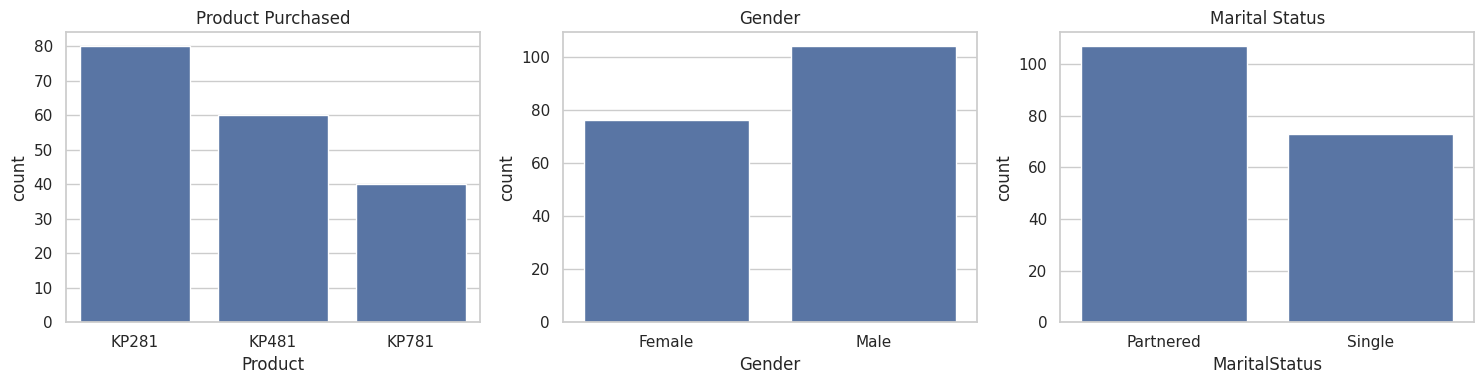

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='Product', ax=axes[0])
axes[0].set_title('Product Purchased')

sns.countplot(data=df, x='Gender', ax=axes[1])
axes[1].set_title('Gender')

sns.countplot(data=df, x='MaritalStatus', ax=axes[2])
axes[2].set_title('Marital Status')

plt.tight_layout()
plt.show()


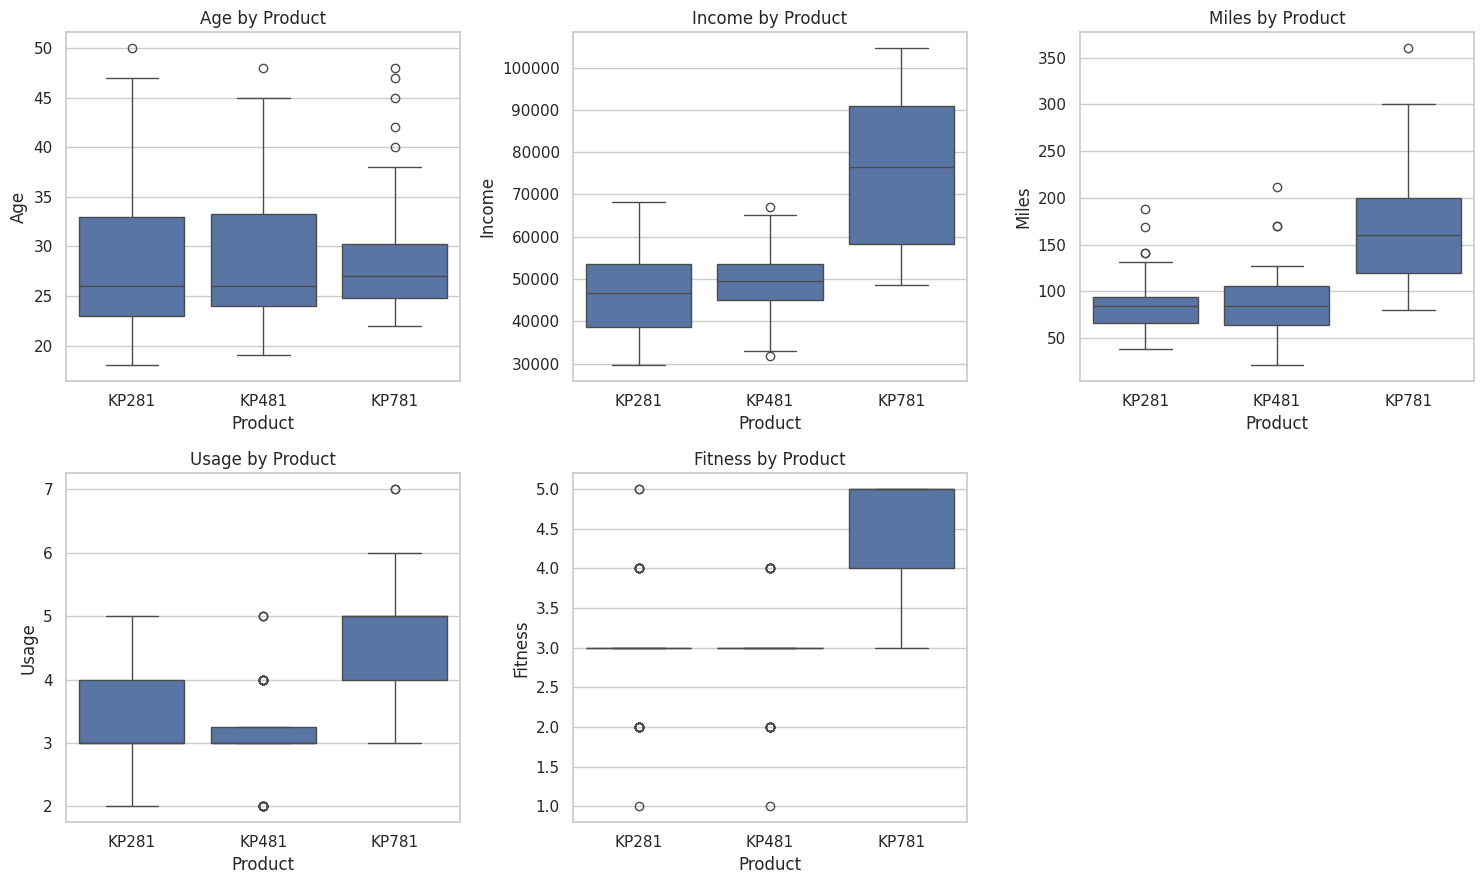

In [ ]:
#### Added code now C

boxplot_vars = ["Age", "Income", "Miles", "Usage", "Fitness"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flatten(), boxplot_vars):
    sns.boxplot(data=df, x="Product", y=col, ax=ax)
    ax.set_title(f"{col} by Product")

# Hide the unused sixth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

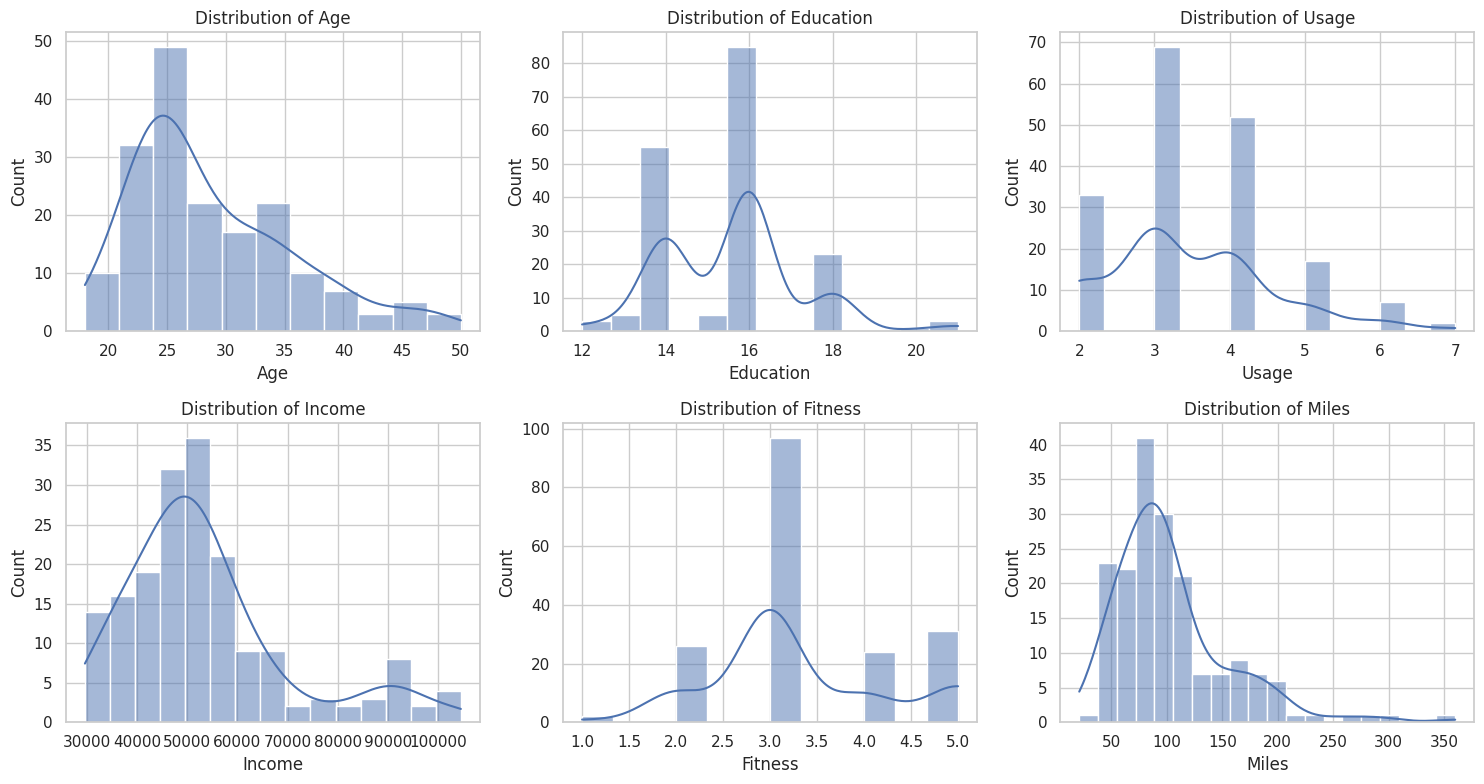

In [ ]:
#### Added code now B
continuous_vars = [
    "Age", "Education", "Usage",
    "Income", "Fitness", "Miles"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), continuous_vars):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

**Insights**
* KP281 has the highest number of customers: 80 (44.44%).
* Male customers represent 57.78% of the dataset.
* Partnered customers represent 59.44%.

### 3.2 Univariate Analysis — Continuous Variables


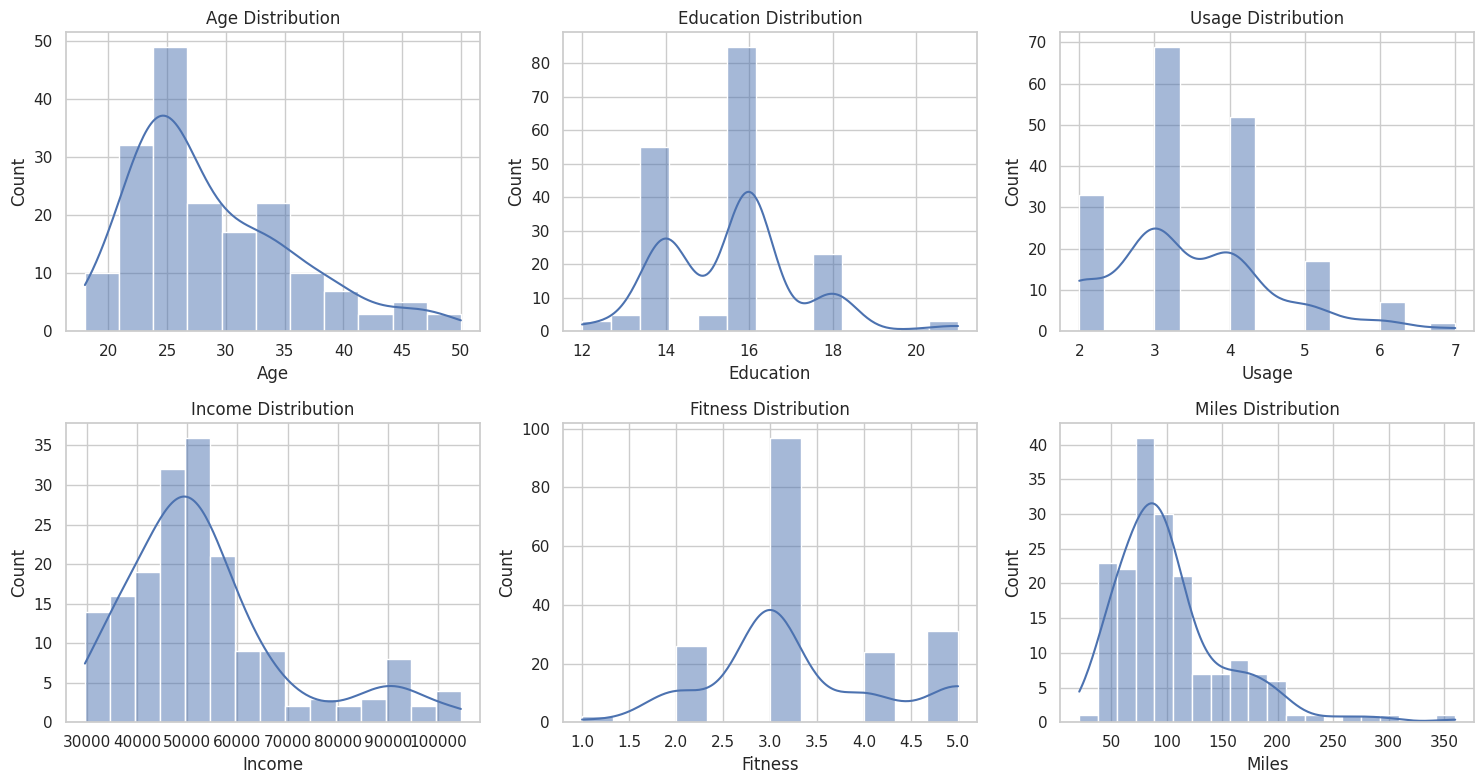

In [ ]:
continuous_cols = [
    'Age',
    'Education',
    'Usage',
    'Income',
    'Fitness',
    'Miles'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), continuous_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'{col} Distribution')
plt.tight_layout()
plt.show()


**Insights**
* Most customers are in their 20s and early 30s.
* Usage is concentrated around 2–4 times per week.
* Fitness level 3 is the most common.
* Income and Miles show wider variation than the other variables.

### 3.3 Marital Status vs Product


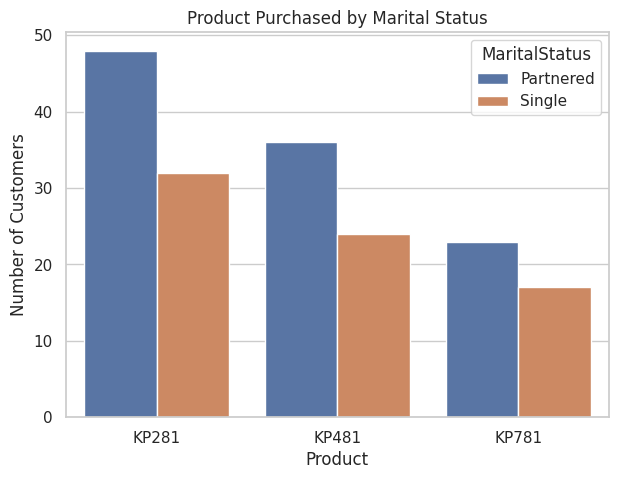

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x='Product',
    hue='MaritalStatus'
)
plt.title('Product Purchased by Marital Status')
plt.xlabel('Product')
plt.ylabel('Number of Customers')
plt.show()


**Insights**
* KP281: 48 partnered, 32 single
* KP481: 36 partnered, 24 single
* KP781: 23 partnered, 17 single
* Partnered percentages are approximately 60%, 60%, and 57.5%.
* Therefore, marital status does not show a strong effect on product purchased.

### 3.4 Age vs Product


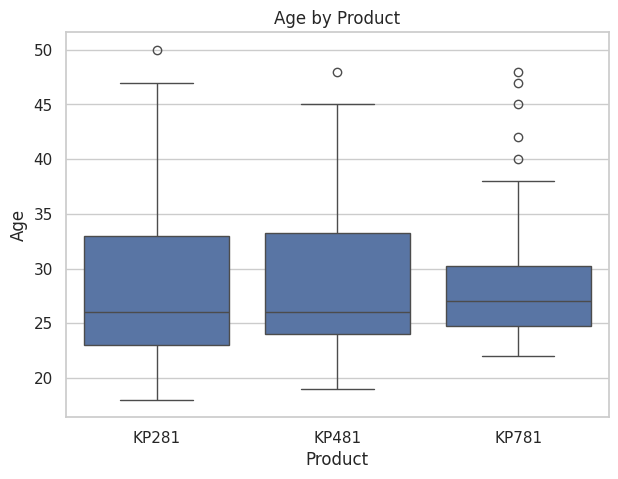

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x='Product',
    y='Age'
)
plt.title('Age by Product')
plt.xlabel('Product')
plt.ylabel('Age')
plt.show()


**Insights**
* Average age: KP281 = 28.55, KP481 = 28.90, KP781 = 29.10
* Difference between KP281 and KP781 is only 0.55 years.
* Age does not show a meaningful effect on product purchased.

### 3.5 Other Numerical Variables vs Product
These boxplots help identify which customer characteristics differ across products.


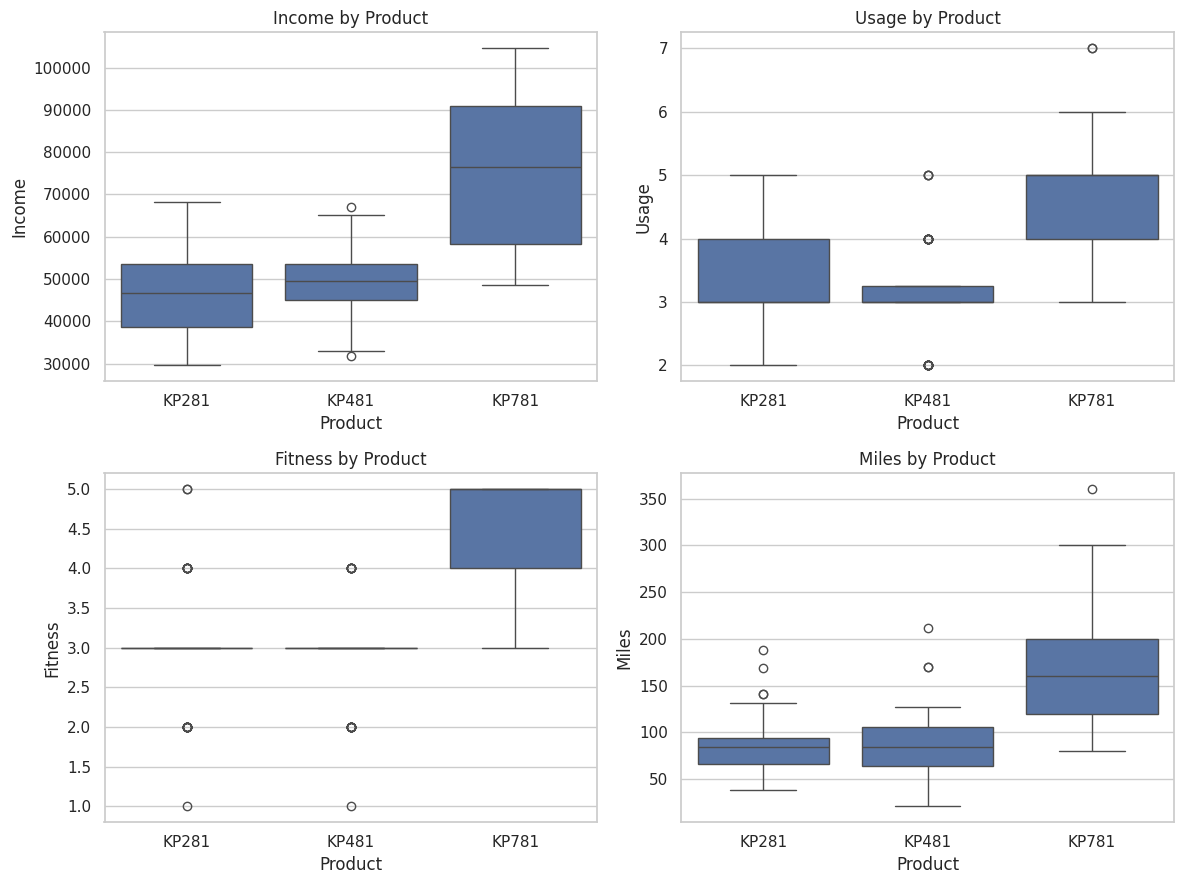

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=df, x='Product', y='Income', ax=axes[0, 0])
axes[0, 0].set_title('Income by Product')

sns.boxplot(data=df, x='Product', y='Usage', ax=axes[0, 1])
axes[0, 1].set_title('Usage by Product')

sns.boxplot(data=df, x='Product', y='Fitness', ax=axes[1, 0])
axes[1, 0].set_title('Fitness by Product')

sns.boxplot(data=df, x='Product', y='Miles', ax=axes[1, 1])
axes[1, 1].set_title('Miles by Product')

plt.tight_layout()
plt.show()


**Insights**
* KP781 average income = \$75,442, compared with $46,418 for KP281.
* KP781 average usage = 4.78, compared with about 3.1 for KP281/KP481.
* KP781 average fitness = 4.63, compared with about 3 for KP281/KP481.
* KP781 average miles = 166.90, compared with 82.79 for KP281.
* Therefore, income, usage, fitness, and miles show stronger differences across products.

### 3.6 Correlation Heatmap


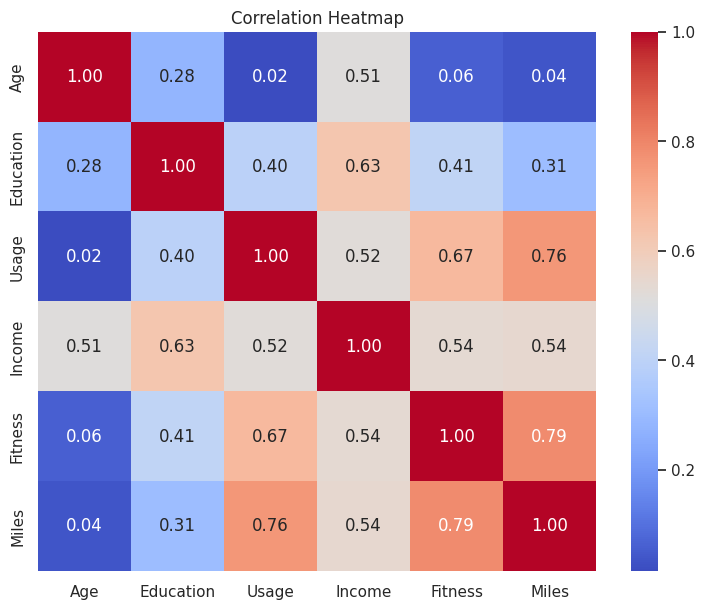

In [ ]:
numeric_cols = [
    'Age',
    'Education',
    'Usage',
    'Income',
    'Fitness',
    'Miles'
]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()


**Insights**
* Usage and Fitness: 0.67
* Education and Income: 0.63
* Income and Usage: 0.52
* Age and Miles: 0.03
* The strongest relationship is between Usage and Fitness.

### 3.7 Pairplot


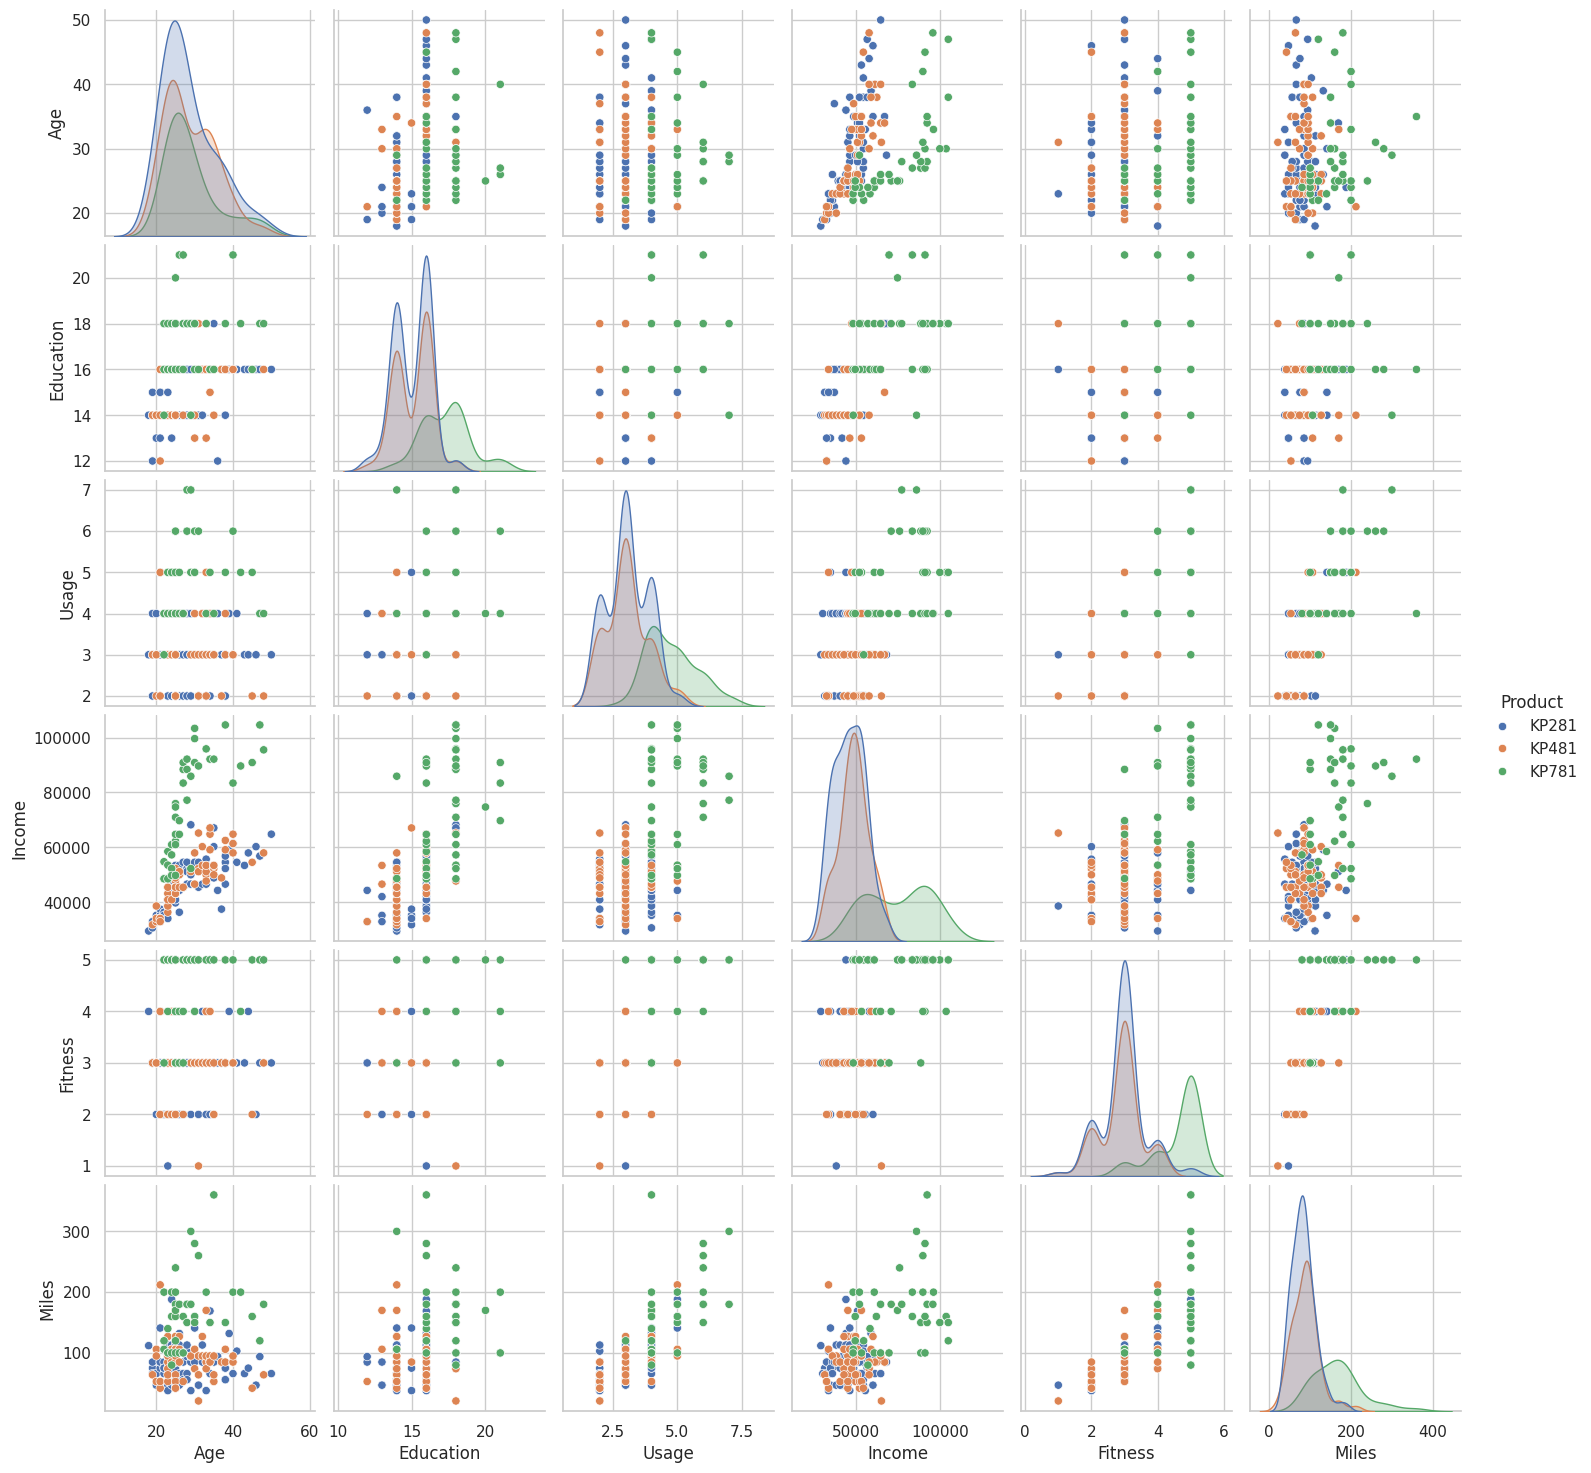

In [ ]:
sns.pairplot(
    df,
    vars=[
        'Age',
        'Education',
        'Usage',
        'Income',
        'Fitness',
        'Miles'
    ],
    hue='Product'
)
plt.show()


**Insights**
* KP781 customers are concentrated toward higher income, usage, fitness, and miles.
* Age has considerable overlap across all products.
* The pairplot supports the differences observed in the boxplots.


## 4. Missing Value & Outlier Detection

### 4.1 Missing Values


In [ ]:
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
Product          0
Age              0
Gender           0
Education        0
MaritalStatus    0
Usage            0
Fitness          0
Income           0
Miles            0
dtype: int64


**Insights**
* All columns contain 0 missing values.
* No missing-value treatment is required.

### 4.2 Outliers Using Boxplots


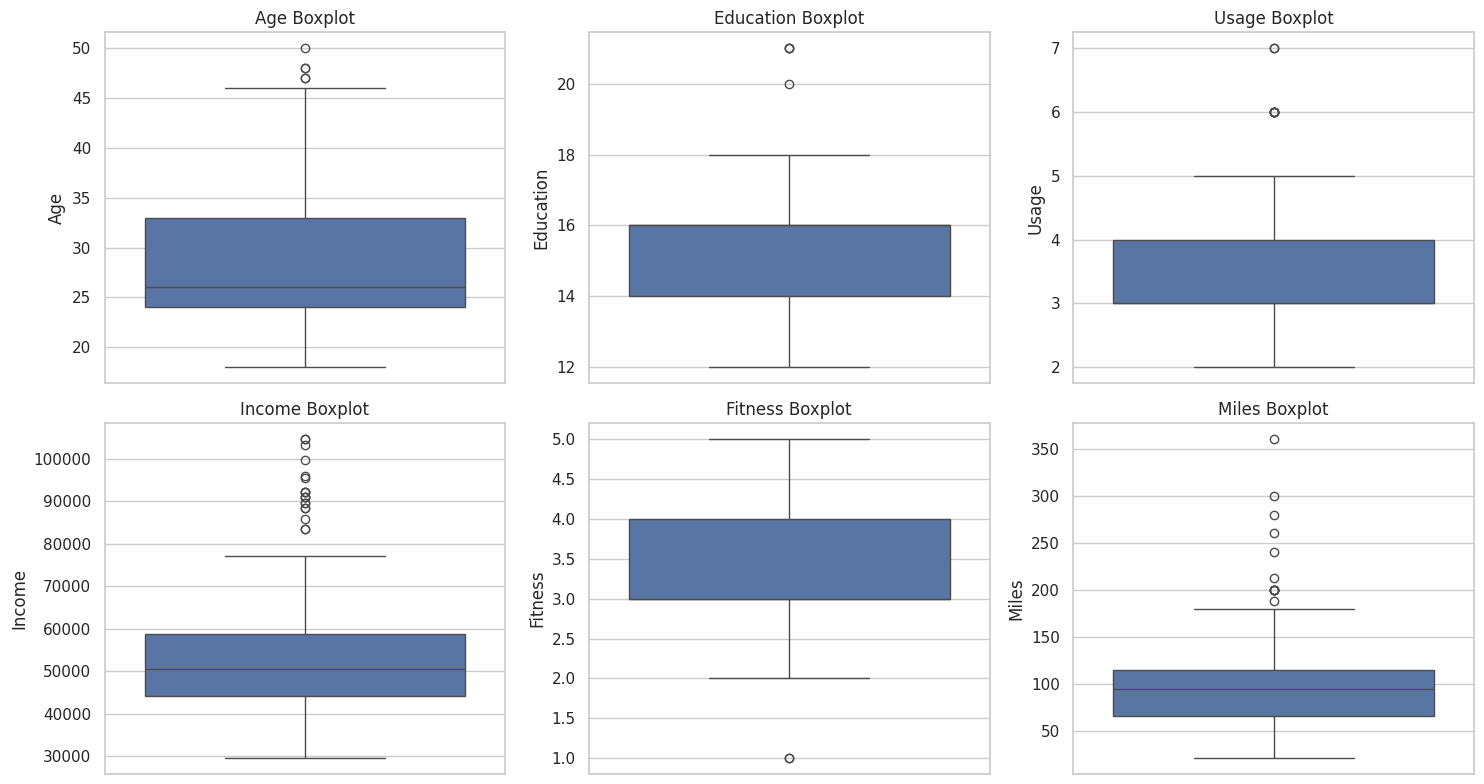

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f'{col} Boxplot')
plt.tight_layout()
plt.show()


**Insights**
* Income and Miles show the clearest extreme observations.
* These observations should be investigated rather than automatically removed because they may represent genuine high-income or high-activity customers.




In [ ]:
#added code
### 4.4 Outlier Detection using the 1.5 × IQR Rule

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_count = len(outliers)
    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_summary.append({
        "Attribute": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(outlier_percentage, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Attribute,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,10.500,46.500,5,2.78
1,Education,11.000,19.000,4,2.22
2,Usage,1.500,5.500,9,5.00
3,Income,22144.875,80581.875,19,10.56
4,Fitness,1.500,5.500,2,1.11
5,Miles,-7.125,187.875,13,7.22


**Insights :**

- **1.5 × IQR Rule:** Potential outliers were identified using the standard 1.5 × IQR method for the six numerical attributes.

- **Income and Miles:** These variables show the clearest extreme observations, consistent with the boxplot and mean-versus-median analysis.

- **Business Interpretation:** The extreme values in Income and Miles may represent genuine customers with higher purchasing power or higher expected treadmill usage, rather than data-entry errors.

- **Outlier Handling Decision:** The identified outliers will **not be removed** from the dataset. There is no evidence that these observations are incorrect, and removing them could eliminate meaningful customer segments.

- **Final Decision:** The original dataset will be retained for further analysis, while the identified outliers will be considered when interpreting customer profiles and product preferences.

### 4.3 Mean vs Median

In [ ]:
mean_median = df[numeric_cols].describe().T[
    ['mean', '50%']
]
mean_median.columns = ['Mean', 'Median']
mean_median['Mean - Median'] = (
    mean_median['Mean'] - mean_median['Median']
)
display(mean_median)


,Mean,Median,Mean - Median
Age,28.788889,26.0,2.788889
Education,15.572222,16.0,-0.427778
Usage,3.455556,3.0,0.455556
Income,53719.577778,50596.5,3123.077778
Fitness,3.311111,3.0,0.311111
Miles,103.194444,94.0,9.194444


**Insights**
* **Income:** Mean = \$53,719.58, Median = $50,596.50
* **Miles:** Mean = 103.19, Median = 94
* The larger differences between mean and median for Income and Miles support the boxplot observation of extreme values.


## 5. Business Insights Based on Non-Graphical and Visual Analysis
This section brings together the findings required by the evaluation criteria, including customer profiling and probability from the case-study requirements.

### Customer Profiling


In [ ]:
profile = df.groupby('Product', observed=True).agg(
    Customers=('Product', 'size'),
    Avg_Age=('Age', 'mean'),
    Avg_Education=('Education', 'mean'),
    Avg_Usage=('Usage', 'mean'),
    Avg_Income=('Income', 'mean'),
    Avg_Fitness=('Fitness', 'mean'),
    Avg_Miles=('Miles', 'mean')
).round(2)
display(profile)


,Customers,Avg_Age,Avg_Education,Avg_Usage,Avg_Income,Avg_Fitness,Avg_Miles
Product,,,,,,,
KP281,80,28.55,15.04,3.09,46418.02,2.96,82.79
KP481,60,28.90,15.12,3.07,48973.65,2.90,87.93
KP781,40,29.10,17.32,4.78,75441.58,4.62,166.90


**Insights:**

**KP281:** 80 customers; moderate usage and fitness; average income about \$46,418.

**KP481:** 60 customers; profile is similar to KP281 on age, usage, and fitness.

**KP781:** 40 customers; higher income ($75,442), usage (4.78), fitness (4.63) and miles (166.90).




Missing Values:
Product          0
Age              0
Gender           0
Education        0
MaritalStatus    0
Usage            0
Fitness          0
Income           0
Miles            0
dtype: int64

Total Missing Values: 0

Mean vs Median:


,mean,median
Age,28.788889,26.0
Education,15.572222,16.0
Usage,3.455556,3.0
Income,53719.577778,50596.5
Fitness,3.311111,3.0
Miles,103.194444,94.0


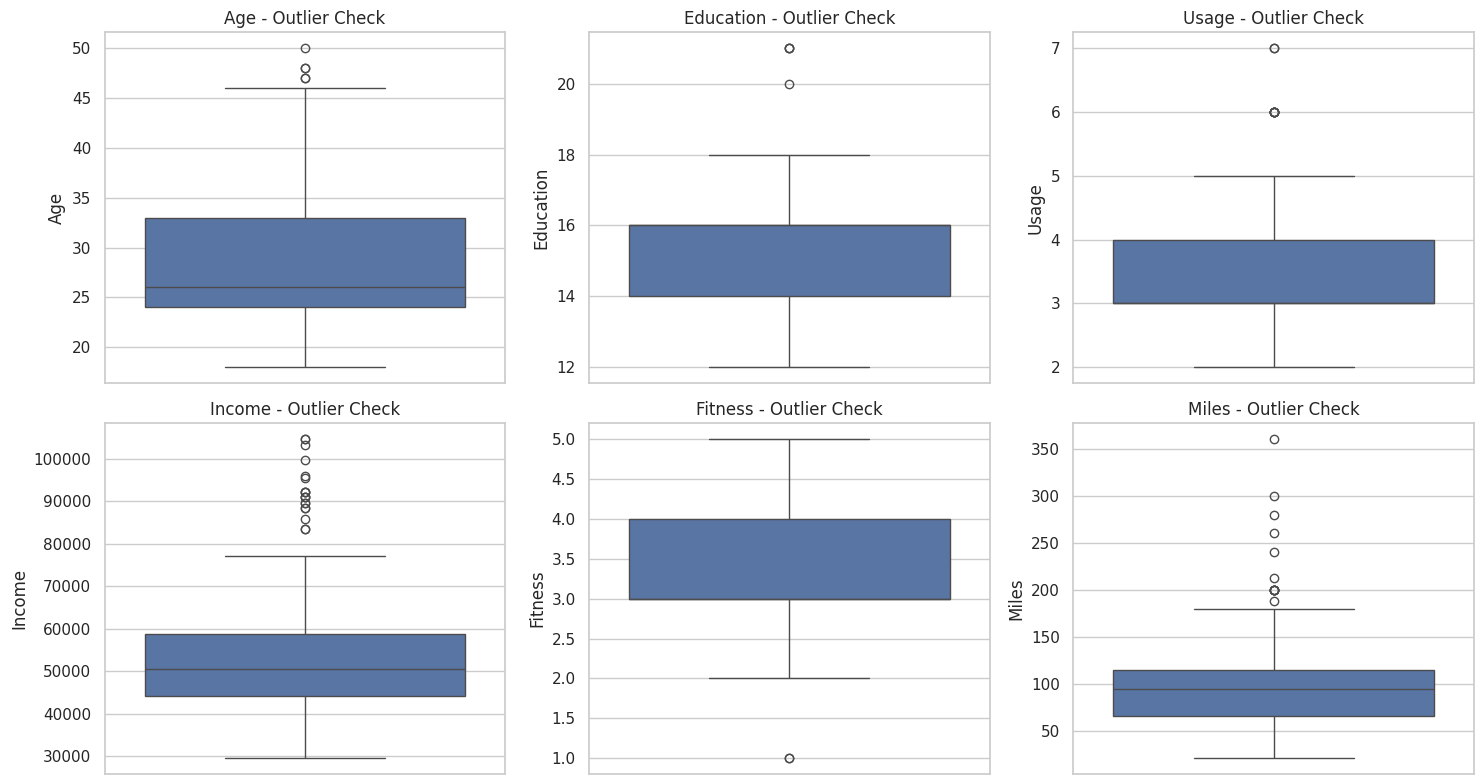

In [ ]:
## added code
#added code

# E. Missing Values and Outlier Detection

# 1. Check for missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# 2. Compare mean and median to understand potential skewness
numeric_cols = [
    "Age", "Education", "Usage",
    "Income", "Fitness", "Miles"
]

print("\nMean vs Median:")
display(df[numeric_cols].agg(["mean", "median"]).T)

# 3. Visualize potential outliers using boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"{col} - Outlier Check")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()


### Insights: Missing Values and Outlier Detection

- **Missing Values:** The dataset contains no missing values.
- **Age:** The median age is 26 years, while the mean is approximately 28.79 years.
- **Education:** Education ranges from 12 to 21 years.
- **Usage:** Weekly treadmill usage ranges from 2 to 7 times.
- **Income:** Income ranges from \$29,562 to $104,581, indicating variation in customers' income levels.
- **Fitness:** Fitness ratings range from 1 to 5.
- **Miles:** Expected weekly miles range from 21 to 360, showing variation in customers' expected treadmill usage.

**Overall Insight:** The boxplots help identify potential outliers across the six attributes. These values should be investigated before taking action, as they may reflect genuine differences among customers rather than data errors.

### Marginal Probability

In [ ]:
marginal_probability = pd.crosstab(
    df['Product'],
    columns='Percentage',
    normalize=True
).mul(100).round(2)
display(marginal_probability)


col_0,Percentage
Product,
KP281,44.44
KP481,33.33
KP781,22.22


**Insights**

So, based on this dataset:
* 44.44% of customers purchased KP281.
* 33.33% purchased KP481.
* 22.22% purchased KP781.




In [ ]:
#####code addded
for col in [
    "Product", "Gender", "MaritalStatus",
    "Education", "Usage", "Fitness"
]:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts().sort_index())


--- Product ---
Unique values: 3
Product
KP281    80
KP481    60
KP781    40
Name: count, dtype: int64

--- Gender ---
Unique values: 2
Gender
Female     76
Male      104
Name: count, dtype: int64

--- MaritalStatus ---
Unique values: 2
MaritalStatus
Partnered    107
Single        73
Name: count, dtype: int64

--- Education ---
Unique values: 8
Education
12     3
13     5
14    55
15     5
16    85
18    23
20     1
21     3
Name: count, dtype: int64

--- Usage ---
Unique values: 6
Usage
2    33
3    69
4    52
5    17
6     7
7     2
Name: count, dtype: int64

--- Fitness ---
Unique values: 5
Fitness
1     2
2    26
3    97
4    24
5    31
Name: count, dtype: int64


### Conditional Probability — Male Customer Buying KP781

In [ ]:
gender_product = pd.crosstab(
    df['Gender'],
    df['Product']
)
display(gender_product)

p_kp781_given_male = (
    gender_product.loc['Male', 'KP781']
    / gender_product.loc['Male'].sum()
)
p_kp781_given_female = (
    gender_product.loc['Female', 'KP781']
    / gender_product.loc['Female'].sum()
)

print(f"P(KP781 | Male) = {p_kp781_given_male:.2%}")
print(f"P(KP781 | Female) = {p_kp781_given_female:.2%}")


Product,KP281,KP481,KP781
Gender,,,
Female,40,29,7
Male,40,31,33


P(KP781 | Male) = 31.73%
P(KP781 | Female) = 9.21%


**Insights**
* Male customers = 104
* Male customers who purchased KP781 = 33

Therefore:
* P(KP781 | Male) = 33/104 = 31.73\%

* P(KP781 | Female) = 9.21\%

KP781 is therefore much more concentrated among male customers in this dataset.

### Overall Business Insights
* Age and marital status show little difference across products.
* Income, usage, fitness, miles, education, and gender show stronger differences.
* KP781 customers have a distinct higher-income and higher-activity profile.
* Usage and Fitness have a positive correlation of 0.67.
* The customer profiles can therefore be broadly differentiated by activity level and income.



**Comments on the range of attributes:**
* Age ranges from 18 to 50 years, with a concentration in the mid-20s to early 30s. Income spans from \$29k to $104k. Usage averages 3-4 days a week, and fitness ratings mostly hover around a self-rated 3.

**Comments on the distribution of the variables and relationship between them:**
* Income and Miles are slightly right-skewed with some high-end outliers. There is a strong positive relationship between Usage and Fitness (0.67) and Income and Education (0.63).

**Comments for each univariate and bivariate plot:**
* **Univariate:** KP281 is the clear best-seller. The customer base leans slightly male and partnered.
* **Bivariate:** Marital status and Age show almost no effect on the product purchased. However, Income, Fitness, and Miles show distinct segmentation, with KP781 dominating the higher ends of all three metrics.



## 6. Recommendations
* Position KP281 for the broader customer base, since it represents 44.44% of customers.
* Target KP781 toward higher-income customers, based on its average income of $75,442.
* Target KP781 toward frequent users, based on its average usage of 4.78 times/week.
* Target KP781 toward highly fit customers, based on its average fitness score of 4.63.
* Use activity and mileage when identifying potential KP781 customers, since KP781 customers average 166.90 miles.
* Consider male customers as an important KP781 target group, since 82.5% of KP781 customers are male.
* Do not make age the main targeting factor, because average age is only 28.55–29.10 years across products.
* Do not make marital status the main targeting factor, because partnered customers represent approximately 57.5–60% across products.
* Use high usage and high fitness together when identifying potential KP781 customers, as both show clear differences from KP281 and KP481.
* Keep product positioning distinct based on the observed customer profiles: broader moderate-use customers for KP281, middle-segment customers for KP481, and higher-income/high-activity customers for KP781.
